In [1]:
!git clone https://github.com/MansiTechie/YantraDrishti.git
%cd /content/YantraDrishti
!git status

Cloning into 'YantraDrishti'...
remote: Enumerating objects: 126, done.
remote: Counting objects: 100% (126/126), done.
remote: Compressing objects: 100% (87/87), done.
remote: Total 126 (delta 33), reused 74 (delta 18), pack-reused 0 (from 0)
Receiving objects: 100% (126/126), 28.37 MiB | 20.66 MiB/s, done.
Resolving deltas: 100% (33/33), done.
/content/YantraDrishti
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [2]:
!git fetch origin
!git branch -a

* main
  remotes/origin/HEAD -> origin/main
  remotes/origin/develop
  remotes/origin/feature/backend-day3-inference
  remotes/origin/feature/backend-setup
  remotes/origin/feature/day2-ml-review-fixes
  remotes/origin/feature/ml-day2
  remotes/origin/feature/ml-day3-finalization
  remotes/origin/feature/platform-day2
  remotes/origin/main


In [3]:
%cd /content/YantraDrishti

!git fetch origin
!git checkout develop
!git pull --ff-only origin develop
!git checkout -b feature/ml-day4-xgboost

import os

files = [
    "ml/notebooks/YantraDrishti_Day3_FD001_RUL_Baseline.ipynb",
    "ml/models/rul_baseline.joblib",
    "ml/metrics/day3_rul_metrics.json",
    "ml/reports/day3_rul_baseline.md",
    "ml/notebooks/YantraDrishti_Day2_FD001_Data_Preparation.ipynb"
]

for f in files:
    print(("FOUND  " if os.path.exists(f) else "MISSING ") + f)

/content/YantraDrishti
branch 'develop' set up to track 'origin/develop'.
Switched to a new branch 'develop'
From https://github.com/MansiTechie/YantraDrishti
 * branch            develop    -> FETCH_HEAD
Already up to date.
Switched to a new branch 'feature/ml-day4-xgboost'
FOUND  ml/notebooks/YantraDrishti_Day3_FD001_RUL_Baseline.ipynb
FOUND  ml/models/rul_baseline.joblib
FOUND  ml/metrics/day3_rul_metrics.json
FOUND  ml/reports/day3_rul_baseline.md
FOUND  ml/notebooks/YantraDrishti_Day2_FD001_Data_Preparation.ipynb


In [4]:
import os, json

base = "/content/YantraDrishti"

with open(f"{base}/ml/metrics/day3_rul_metrics.json") as f:
    print("DAY 3 METRICS")
    print(json.dumps(json.load(f), indent=2))

with open(f"{base}/ml/reports/day3_rul_baseline.md") as f:
    print("\nDAY 3 REPORT")
    print(f.read())

for filename in [
    "ml/notebooks/YantraDrishti_Day2_FD001_Data_Preparation.ipynb",
    "ml/notebooks/YantraDrishti_Day3_FD001_RUL_Baseline.ipynb"
]:
    path = f"{base}/{filename}"
    print(f"\n{filename}")

    with open(path) as f:
        notebook = json.load(f)

    for i, cell in enumerate(notebook["cells"]):
        if cell["cell_type"] == "code":
            source = "".join(cell["source"])
            keywords = [
                "feature", "RUL", "NASA", "RMSE", "MAE",
                "train_test", "RandomForest", "DummyRegressor",
                "train_prepared", "validation_prepared"
            ]
            if any(k.lower() in source.lower() for k in keywords):
                print(f"\nCELL {i}\n{source[:3500]}")

print("\nPREPARED FILES")

for root, dirs, files in os.walk(base):
    for name in files:
        if name in [
            "train_prepared.csv",
            "validation_prepared.csv",
            "test_prepared.csv",
            "rul_baseline.joblib"
        ]:
            print(os.path.join(root, name))

DAY 3 METRICS
{
  "dataset": "NASA C-MAPSS FD001",
  "model_name": "RandomForestRegressor",
  "model_version": "1.0.0",
  "parameters": {
    "bootstrap": true,
    "ccp_alpha": 0.0,
    "criterion": "squared_error",
    "max_depth": 15,
    "max_features": 1.0,
    "max_leaf_nodes": null,
    "max_samples": null,
    "min_impurity_decrease": 0.0,
    "min_samples_leaf": 2,
    "min_samples_split": 5,
    "min_weight_fraction_leaf": 0.0,
    "monotonic_cst": null,
    "n_estimators": 150,
    "n_jobs": -1,
    "oob_score": false,
    "random_state": 42,
    "verbose": 0,
    "warm_start": false
  },
  "features": [
    "cycle",
    "setting_1",
    "setting_2",
    "setting_3",
    "sensor_01",
    "sensor_02",
    "sensor_03",
    "sensor_04",
    "sensor_05",
    "sensor_06",
    "sensor_07",
    "sensor_08",
    "sensor_09",
    "sensor_10",
    "sensor_11",
    "sensor_12",
    "sensor_13",
    "sensor_14",
    "sensor_15",
    "sensor_16",
    "sensor_17",
    "sensor_18",
    "se

In [5]:
from pathlib import Path
import json, joblib, pandas as pd, numpy as np
import sklearn, xgboost as xgb

ROOT = Path("/content/YantraDrishti")
DATA = ROOT / "datasets/processed"

train_df = pd.read_csv(DATA / "train_prepared.csv")
val_df = pd.read_csv(DATA / "validation_prepared.csv")

with open(ROOT / "ml/metrics/day3_rul_metrics.json") as f:
    day3_metrics = json.load(f)

with open(DATA / "split_manifest.json") as f:
    manifest = json.load(f)

features = day3_metrics["features"]

assert len(features) == 46
assert features == manifest["feature_columns"]
assert "RUL" not in features
assert "unit_number" not in features
assert train_df[features].notna().all().all()
assert val_df[features].notna().all().all()
assert set(train_df.unit_number).isdisjoint(set(val_df.unit_number))

X_train = train_df[features]
y_train = train_df["RUL"]
X_val = val_df[features]
y_val = val_df["RUL"]

rf_artifact = joblib.load(ROOT / "ml/models/rul_baseline.joblib")
rf_model = rf_artifact["model"]

print("XGBoost version:", xgb.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Features:", len(features))
print("Train:", X_train.shape, "Validation:", X_val.shape)
print("Train engines:", train_df.unit_number.nunique())
print("Validation engines:", val_df.unit_number.nunique())
print("Feature order verified:", features == rf_artifact["features"])
print("Engine overlap:", len(set(train_df.unit_number) & set(val_df.unit_number)))
print("Data verification successful")

XGBoost version: 3.4.1
Scikit-learn: 1.6.1
Features: 46
Train: (16561, 46) Validation: (4070, 46)
Train engines: 80
Validation engines: 20
Feature order verified: True
Engine overlap: 0
Data verification successful


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeRegressor from version 1.7.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RandomForestRegressor from version 1.7.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [6]:
import time
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

def nasa_score(actual, predicted):
    d = np.asarray(predicted) - np.asarray(actual)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_val)

rf_params = {
    "n_estimators": 150,
    "max_depth": 15,
    "min_samples_split": 5,
    "min_samples_leaf": 2,
    "random_state": 42,
    "n_jobs": -1
}

rf_model = RandomForestRegressor(**rf_params)
start = time.time()
rf_model.fit(X_train, y_train)
rf_time = time.time() - start
rf_pred = rf_model.predict(X_val)

xgb_params = {
    "objective": "reg:squarederror",
    "n_estimators": 500,
    "max_depth": 4,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 5,
    "reg_lambda": 5,
    "reg_alpha": 0,
    "random_state": 42,
    "n_jobs": -1,
    "tree_method": "hist"
}

xgb_model = XGBRegressor(**xgb_params)
start = time.time()
xgb_model.fit(X_train, y_train, verbose=False)
xgb_time = time.time() - start
xgb_pred = xgb_model.predict(X_val)

models = {
    "Dummy Regressor": dummy_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred
}

results = []

for name, pred in models.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_val, pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, pred)),
        "NASA Score": nasa_score(y_val, pred)
    })

comparison = pd.DataFrame(results)
print(comparison.round(3).to_string(index=False))
print("\nRandom Forest training time:", round(rf_time, 2), "seconds")
print("XGBoost training time:", round(xgb_time, 2), "seconds")
print("\nDay 3 RF MAE reference:", day3_metrics["mae"])
print("Reproduced RF MAE:", mean_absolute_error(y_val, rf_pred))
print("Day 3 RF RMSE reference:", day3_metrics["rmse"])
print("Reproduced RF RMSE:", np.sqrt(mean_squared_error(y_val, rf_pred)))
print("Day 3 RF NASA reference:", day3_metrics["nasa_score"])
print("Reproduced RF NASA:", nasa_score(y_val, rf_pred))

          Model    MAE   RMSE   NASA Score
Dummy Regressor 55.363 65.715 19351068.755
  Random Forest 23.474 30.871   253571.045
        XGBoost 22.490 29.675   161146.544

Random Forest training time: 44.1 seconds
XGBoost training time: 1.31 seconds

Day 3 RF MAE reference: 23.474377113397434
Reproduced RF MAE: 23.474377113397434
Day 3 RF RMSE reference: 30.87114635145243
Reproduced RF RMSE: 30.87114635145243
Day 3 RF NASA reference: 253571.04539612017
Reproduced RF NASA: 253571.04539612017


All 46 features:
        feature  importance
          cycle    0.375866
      sensor_11    0.167190
      sensor_04    0.083362
      sensor_12    0.073095
      sensor_07    0.038843
      sensor_09    0.036222
      sensor_15    0.024787
      sensor_14    0.017482
      sensor_20    0.016856
      sensor_21    0.015413
      sensor_08    0.014777
      sensor_02    0.013513
      sensor_17    0.012962
      sensor_03    0.008954
      sensor_13    0.008452
      setting_2    0.005962
sensor_09_delta    0.005704
sensor_14_delta    0.005659
sensor_17_delta    0.005493
sensor_21_delta    0.005492
sensor_11_delta    0.005403
sensor_07_delta    0.005263
sensor_12_delta    0.005229
sensor_04_delta    0.005185
sensor_02_delta    0.005134
sensor_06_delta    0.004987
sensor_03_delta    0.004953
sensor_13_delta    0.004891
sensor_20_delta    0.004832
      setting_1    0.004766
sensor_15_delta    0.004709
sensor_08_delta    0.004283
      sensor_06    0.004282
      sensor_01    0.000000
   

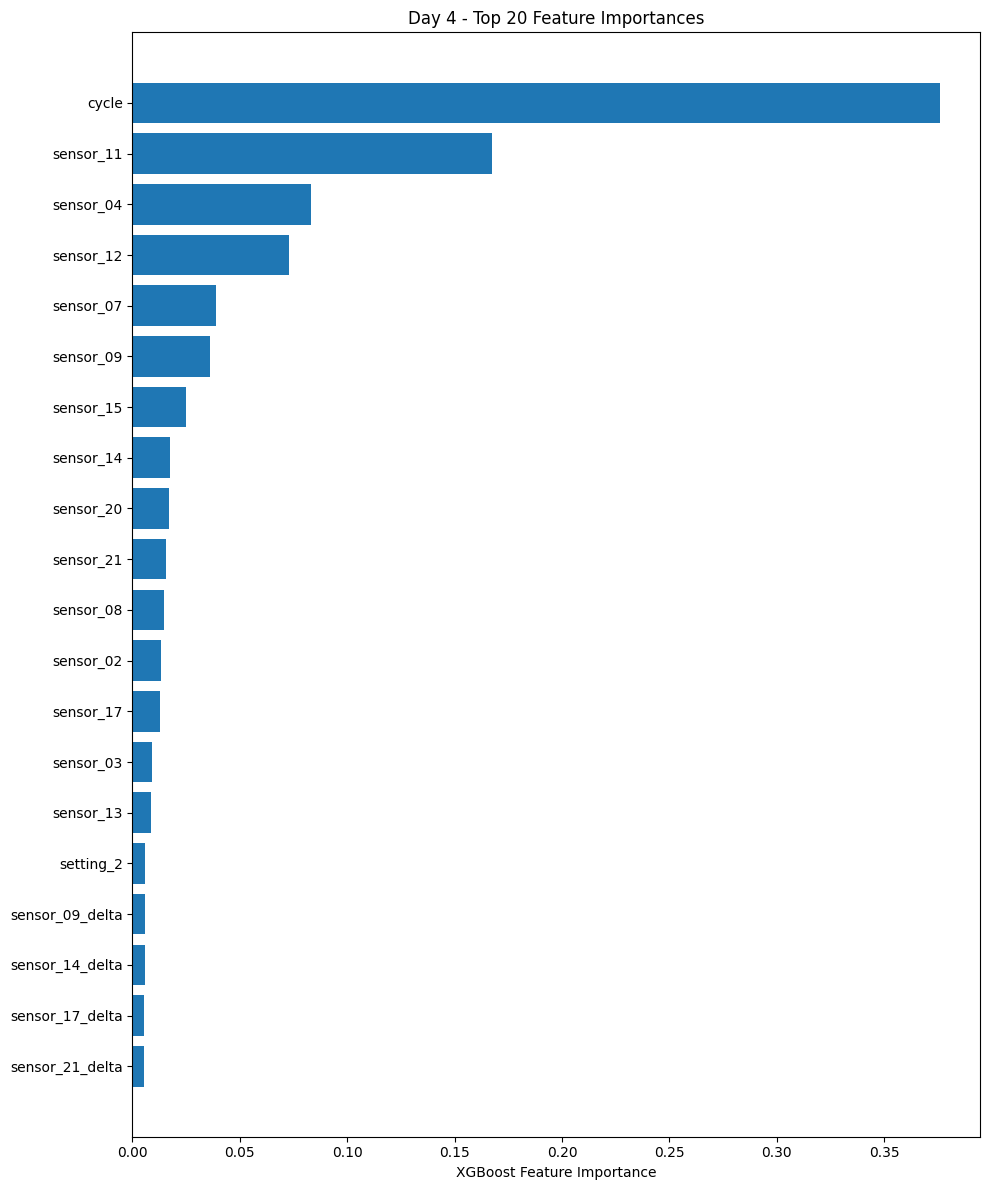

In [7]:
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "feature": features,
    "importance": xgb_model.feature_importances_
}).sort_values("importance", ascending=False)

assert len(importance_df) == 46
assert importance_df["importance"].notna().all()

print("All 46 features:")
print(importance_df.to_string(index=False))

print("\nTop 15 features:")
print(importance_df.head(15).to_string(index=False))

plt.figure(figsize=(10, 12))
top_features = importance_df.head(20).sort_values("importance")
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("XGBoost Feature Importance")
plt.title("Day 4 - Top 20 Feature Importances")
plt.tight_layout()
plt.show()

In [10]:
from pathlib import Path

REPORT_DIR = ROOT / "ml/reports"
METRICS_DIR = ROOT / "ml/metrics"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

report_path = REPORT_DIR / "day4_rul_model_comparison.md"
metrics_path = METRICS_DIR / "day4_rul_comparison.json"

report_path.write_text(report, encoding="utf-8")

print("Report saved:", report_path)
print("JSON exists:", metrics_path.exists())
print("Report size:", report_path.stat().st_size)

Report saved: /content/YantraDrishti/ml/reports/day4_rul_model_comparison.md
JSON exists: False
Report size: 2419


In [12]:
import json
import numpy as np
import pandas as pd
import sklearn
import xgboost as xgb
from pathlib import Path
from datetime import datetime, timezone
from sklearn.metrics import mean_absolute_error, mean_squared_error

METRICS_DIR = ROOT / "ml/metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

metrics_path = METRICS_DIR / "day4_rul_comparison.json"

importance_df = pd.DataFrame({
    "feature": features,
    "importance": xgb_model.feature_importances_
}).sort_values("importance", ascending=False)

def get_metrics(actual, predicted):
    d = np.asarray(predicted) - np.asarray(actual)
    return {
        "mae": float(mean_absolute_error(actual, predicted)),
        "rmse": float(np.sqrt(mean_squared_error(actual, predicted))),
        "nasa_score": float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))
    }

day4_metrics = {
    "dataset": "NASA C-MAPSS FD001",
    "evaluation_split": "Engine-wise validation",
    "feature_count": len(features),
    "features": features,
    "train_rows": len(X_train),
    "validation_rows": len(X_val),
    "train_engines": int(train_df.unit_number.nunique()),
    "validation_engines": int(val_df.unit_number.nunique()),
    "train_validation_engine_overlap": 0,
    "target": "RUL",
    "random_seed": 42,
    "models": {
        "Dummy Regressor": {
            "hyperparameters": {"strategy": "mean"},
            **get_metrics(y_val, dummy_pred)
        },
        "Random Forest": {
            "hyperparameters": rf_model.get_params(),
            "training_seconds": float(rf_time),
            **get_metrics(y_val, rf_pred)
        },
        "XGBoost": {
            "hyperparameters": xgb_model.get_params(),
            "training_seconds": float(xgb_time),
            **get_metrics(y_val, xgb_pred)
        }
    },
    "feature_importance": importance_df.to_dict(orient="records"),
    "validation_predictions": [
        {
            "unit_number": int(unit),
            "cycle": int(cycle),
            "actual_RUL": float(actual),
            "dummy_prediction": float(dummy),
            "random_forest_prediction": float(rf),
            "xgboost_prediction": float(xgbp)
        }
        for unit, cycle, actual, dummy, rf, xgbp in zip(
            val_df["unit_number"],
            val_df["cycle"],
            y_val,
            dummy_pred,
            rf_pred,
            xgb_pred
        )
    ],
    "versions": {
        "scikit_learn": sklearn.__version__,
        "xgboost": xgb.__version__
    },
    "test_data_used": False,
    "production_model_replaced": False,
    "evaluation_timestamp": datetime.now(timezone.utc).isoformat()
}

with open(metrics_path, "w") as f:
    json.dump(day4_metrics, f, indent=2)

print("JSON saved:", metrics_path)
print("JSON exists:", metrics_path.exists())
print("JSON size:", metrics_path.stat().st_size)
print("Features:", len(day4_metrics["features"]))
print("Validation predictions:", len(day4_metrics["validation_predictions"]))

JSON saved: /content/YantraDrishti/ml/metrics/day4_rul_comparison.json
JSON exists: True
JSON size: 942520
Features: 46
Validation predictions: 4070


In [13]:

import nbformat
from nbclient import NotebookClient
from pathlib import Path

notebook_path = ROOT / "ml/notebooks/YantraDrishti_Day4_RUL_Model_Comparison.ipynb"
notebook_path.parent.mkdir(parents=True, exist_ok=True)

cells = [
    nbformat.v4.new_markdown_cell(
        "# Day 4 — XGBoost RUL Model Comparison\n"
        "NASA C-MAPSS FD001 | Random Forest vs XGBoost\n\n"
        "This notebook evaluates Dummy Regressor, the Day 3 Random Forest baseline, "
        "and XGBoost using the existing engine-wise validation split. "
        "The test dataset is not used."
    ),
    nbformat.v4.new_code_cell("""
from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import sklearn
import xgboost as xgb
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

ROOT = Path.cwd()
DATA = ROOT / "datasets/processed"

train_df = pd.read_csv(DATA / "train_prepared.csv")
val_df = pd.read_csv(DATA / "validation_prepared.csv")

with open(ROOT / "ml/metrics/day3_rul_metrics.json") as f:
    day3_metrics = json.load(f)

with open(DATA / "split_manifest.json") as f:
    manifest = json.load(f)

features = day3_metrics["features"]

assert len(features) == 46
assert features == manifest["feature_columns"]
assert "RUL" not in features
assert "unit_number" not in features
assert train_df[features].notna().all().all()
assert val_df[features].notna().all().all()
assert set(train_df.unit_number).isdisjoint(set(val_df.unit_number))

X_train = train_df[features]
y_train = train_df["RUL"]
X_val = val_df[features]
y_val = val_df["RUL"]

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Features:", len(features))
print("Train engines:", train_df.unit_number.nunique())
print("Validation engines:", val_df.unit_number.nunique())
print("Engine overlap:", len(set(train_df.unit_number) & set(val_df.unit_number)))
"""),
    nbformat.v4.new_code_cell("""
def nasa_score(actual, predicted):
    d = np.asarray(predicted) - np.asarray(actual)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_val)

rf_params = {
    "n_estimators": 150,
    "max_depth": 15,
    "min_samples_split": 5,
    "min_samples_leaf": 2,
    "random_state": 42,
    "n_jobs": -1
}

rf_model = RandomForestRegressor(**rf_params)
start = time.time()
rf_model.fit(X_train, y_train)
rf_time = time.time() - start
rf_pred = rf_model.predict(X_val)

xgb_params = {
    "objective": "reg:squarederror",
    "n_estimators": 500,
    "max_depth": 4,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 5,
    "reg_lambda": 5,
    "reg_alpha": 0,
    "random_state": 42,
    "n_jobs": -1,
    "tree_method": "hist"
}

xgb_model = XGBRegressor(**xgb_params)
start = time.time()
xgb_model.fit(X_train, y_train, verbose=False)
xgb_time = time.time() - start
xgb_pred = xgb_model.predict(X_val)

comparison = pd.DataFrame([
    {"Model": "Dummy Regressor", "MAE": mean_absolute_error(y_val, dummy_pred), "RMSE": np.sqrt(mean_squared_error(y_val, dummy_pred)), "NASA Score": nasa_score(y_val, dummy_pred)},
    {"Model": "Random Forest", "MAE": mean_absolute_error(y_val, rf_pred), "RMSE": np.sqrt(mean_squared_error(y_val, rf_pred)), "NASA Score": nasa_score(y_val, rf_pred)},
    {"Model": "XGBoost", "MAE": mean_absolute_error(y_val, xgb_pred), "RMSE": np.sqrt(mean_squared_error(y_val, xgb_pred)), "NASA Score": nasa_score(y_val, xgb_pred)}
])

display(comparison.round(3))
print("Random Forest training time:", round(rf_time, 2))
print("XGBoost training time:", round(xgb_time, 2))
"""),
    nbformat.v4.new_code_cell("""
importance_df = pd.DataFrame({
    "feature": features,
    "importance": xgb_model.feature_importances_
}).sort_values("importance", ascending=False)

assert len(importance_df) == 46

display(importance_df)

import matplotlib.pyplot as plt

top_features = importance_df.head(20).sort_values("importance")
plt.figure(figsize=(10, 12))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("XGBoost Feature Importance")
plt.title("Day 4 - Top 20 Feature Importances")
plt.tight_layout()
plt.show()
"""),
    nbformat.v4.new_code_cell("""
def get_metrics(actual, predicted):
    return {
        "mae": float(mean_absolute_error(actual, predicted)),
        "rmse": float(np.sqrt(mean_squared_error(actual, predicted))),
        "nasa_score": nasa_score(actual, predicted)
    }

day4_metrics = {
    "dataset": "NASA C-MAPSS FD001",
    "evaluation_split": "Engine-wise validation",
    "feature_count": len(features),
    "features": features,
    "train_rows": len(X_train),
    "validation_rows": len(X_val),
    "train_engines": int(train_df.unit_number.nunique()),
    "validation_engines": int(val_df.unit_number.nunique()),
    "train_validation_engine_overlap": 0,
    "target": "RUL",
    "random_seed": 42,
    "models": {
        "Dummy Regressor": {"hyperparameters": {"strategy": "mean"}, **get_metrics(y_val, dummy_pred)},
        "Random Forest": {"hyperparameters": rf_params, "training_seconds": float(rf_time), **get_metrics(y_val, rf_pred)},
        "XGBoost": {"hyperparameters": xgb_params, "training_seconds": float(xgb_time), **get_metrics(y_val, xgb_pred)}
    },
    "feature_importance": importance_df.to_dict(orient="records"),
    "validation_predictions": [
        {
            "unit_number": int(unit),
            "cycle": int(cycle),
            "actual_RUL": float(actual),
            "dummy_prediction": float(dummy),
            "random_forest_prediction": float(rf),
            "xgboost_prediction": float(xgbp)
        }
        for unit, cycle, actual, dummy, rf, xgbp in zip(
            val_df["unit_number"], val_df["cycle"], y_val,
            dummy_pred, rf_pred, xgb_pred
        )
    ],
    "versions": {"scikit_learn": sklearn.__version__, "xgboost": xgb.__version__},
    "test_data_used": False,
    "production_model_replaced": False
}

metrics_path = ROOT / "ml/metrics/day4_rul_comparison.json"
metrics_path.parent.mkdir(parents=True, exist_ok=True)

with open(metrics_path, "w") as f:
    json.dump(day4_metrics, f, indent=2)

print("Metrics saved:", metrics_path)
print("Validation predictions:", len(day4_metrics["validation_predictions"]))
"""),
    nbformat.v4.new_markdown_cell(
        "## Conclusion\\n"
        "Compare the validation metrics above. Lower MAE, RMSE, and NASA score indicate "
        "better validation performance. Feature importance is model-based, not causal. "
        "No test-set evaluation or production model replacement was performed."
    )
]

nb = nbformat.v4.new_notebook()
nb.cells = cells
nb.metadata = {
    "kernelspec": {
        "display_name": "Python 3",
        "language": "python",
        "name": "python3"
    }
}

nbformat.write(nb, notebook_path)

client = NotebookClient(nb, timeout=600, kernel_name="python3")
executed_nb = client.execute(cwd=str(ROOT))

nbformat.write(executed_nb, notebook_path)

print("Notebook created and executed:", notebook_path)
print("Notebook exists:", notebook_path.exists())
print("Notebook size:", notebook_path.stat().st_size)


Notebook created and executed: /content/YantraDrishti/ml/notebooks/YantraDrishti_Day4_RUL_Model_Comparison.ipynb
Notebook exists: True
Notebook size: 99697


In [14]:
%cd /content/YantraDrishti

import json
from pathlib import Path

files = [
    Path("ml/notebooks/YantraDrishti_Day4_RUL_Model_Comparison.ipynb"),
    Path("ml/metrics/day4_rul_comparison.json"),
    Path("ml/reports/day4_rul_model_comparison.md")
]

for file in files:
    print(file, "EXISTS:", file.exists(), "SIZE:", file.stat().st_size if file.exists() else 0)

with open(files[1]) as f:
    data = json.load(f)

assert data["feature_count"] == 46
assert len(data["validation_predictions"]) == 4070
assert data["test_data_used"] is False
assert data["production_model_replaced"] is False

print("\nAll artifact checks passed.")

/content/YantraDrishti
ml/notebooks/YantraDrishti_Day4_RUL_Model_Comparison.ipynb EXISTS: True SIZE: 99697
ml/metrics/day4_rul_comparison.json EXISTS: True SIZE: 941201
ml/reports/day4_rul_model_comparison.md EXISTS: True SIZE: 2419

All artifact checks passed.


In [15]:
!git branch --show-current
!git diff --check
!git status --short

feature/ml-day4-xgboost
?? ml/metrics/day4_rul_comparison.json
?? ml/notebooks/YantraDrishti_Day4_RUL_Model_Comparison.ipynb
?? ml/reports/day4_rul_model_comparison.md
